In [9]:
import scipy as sp
import matplotlib.pyplot as plt
from singingmaterials import dos_stats
import csv
import numpy as np

In [34]:
def peak_finder(mp_id,temp,num_peaks,height=1E-6,prominence=1E-6):
    if temp == "athermal":
        data = dos_stats.dos_stats_analysis(mp_id=mp_id)
        density = data["projection"]["total"]["stats"]["athermal"]["densities"]
    else:
        data = dos_stats.dos_stats_analysis(mp_id=mp_id, temp=temp)
        density = data["projection"]["total"]["stats"]["thermal"][str(temp)]["densities"]
    frequency = data["projection"]["total"]["frequencies"]
    peak_indices, peak_properties = sp.signal.find_peaks(density, height=height, prominence=prominence)

    # keep only the num_peaks tallest peaks (in frequency order)
    if num_peaks is not None and len(peak_indices) > num_peaks:
        keep = np.sort(np.argsort(peak_properties["peak_heights"])[::-1][:num_peaks])
        peak_indices = peak_indices[keep]
        peak_properties = {key: value[keep] for key, value in peak_properties.items()}

    plt.plot(frequency, density)
    plt.scatter(frequency[peak_indices], density[peak_indices], color='red', zorder=5)
    plt.xlabel("Frequency")
    plt.ylabel("Density")
    plt.title("Density of States")
    plt.show()

    return data, peak_indices, peak_properties


# write a function to save peak data to a CSV file
def save_peak_data(mp_id, temp, peak_indices, peak_properties, frequency):
    ref_index = np.argmax(peak_properties["peak_heights"])
    dos_ratios = peak_properties["peak_heights"] / peak_properties["peak_heights"][ref_index]
    norm_dos_ratios = dos_ratios / np.sum(dos_ratios)
    freq_ratios = frequency[peak_indices] / frequency[peak_indices][ref_index]

    with open(f"peak_data_{mp_id}_{temp}.csv", "w", newline="") as csvfile:
        writer = csv.writer(csvfile)
        writer.writerow([f"# mp_id: {mp_id}"])
        writer.writerow(["Peak Index", "Peak Height", "Frequency", "DOS Ratio", "Normalized DOS Ratio", "Frequency Ratio"])
        for i, peak_index in enumerate(peak_indices):
            writer.writerow([
                peak_index,
                peak_properties["peak_heights"][i],
                frequency[peak_index],
                dos_ratios[i],
                norm_dos_ratios[i],
                freq_ratios[i]
            ])



Fetching from existing file...


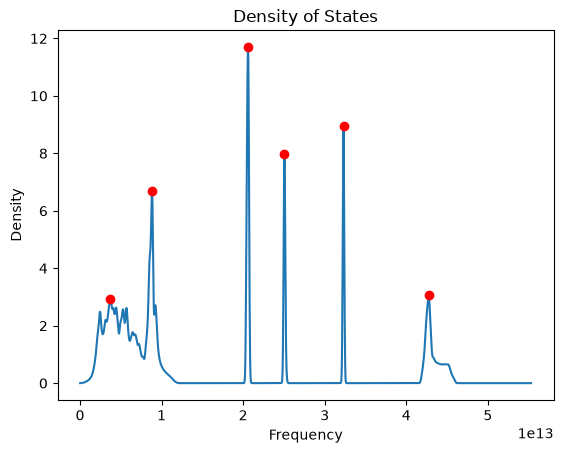

In [10]:
mp_id = "mp-3953"
temp = "athermal"
data, peak_indices, peak_properties = peak_finder(mp_id, temp, num_peaks=6)
save_peak_data(mp_id, temp, peak_indices, peak_properties, data["projection"]["total"]["frequencies"])

Fetching from existing file...


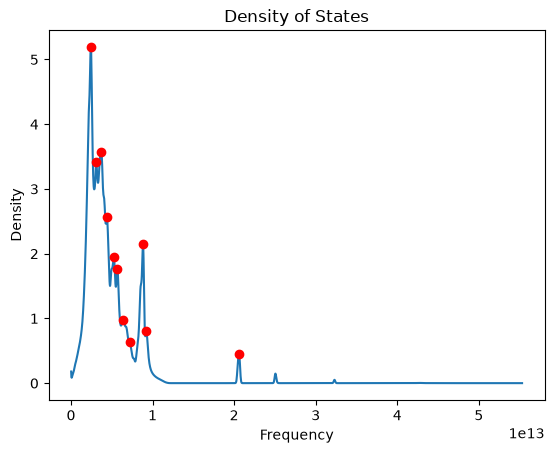

In [21]:
mp_id = "mp-3953"
temp = 300
data, peak_indices, peak_properties = peak_finder(mp_id, temp, num_peaks=11)
save_peak_data(mp_id, temp, peak_indices, peak_properties, data["projection"]["total"]["frequencies"])

Fetching from existing file...


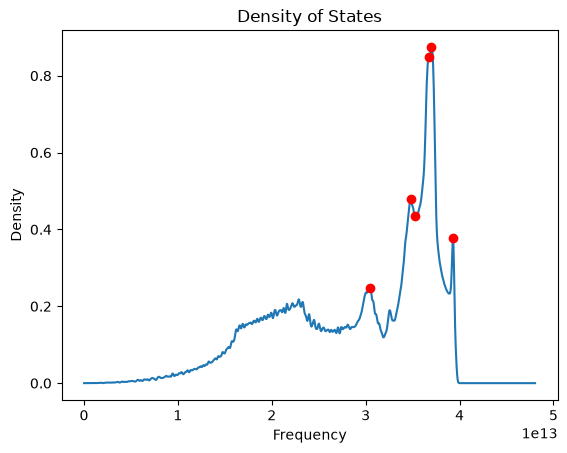

In [ ]:
mp_id = "mp-66"
temp = "athermal"
data, peak_indices, peak_properties = peak_finder(mp_id, temp, num_peaks=6)
save_peak_data(mp_id, temp, peak_indices, peak_properties, data["projection"]["total"]["frequencies"])

Fetching from existing file...


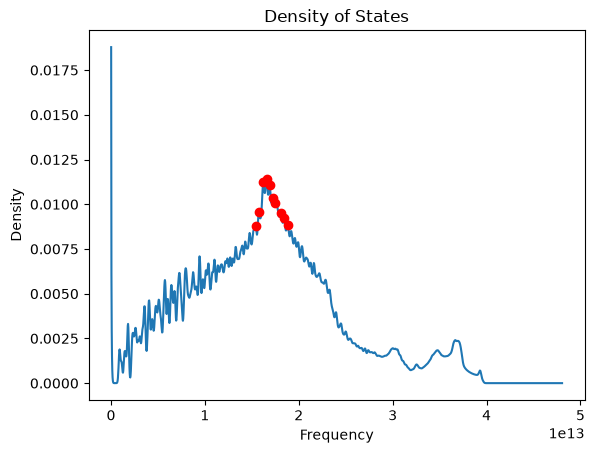

In [22]:
mp_id = "mp-66"
temp = 300
data, peak_indices, peak_properties = peak_finder(mp_id, temp, num_peaks=10)
save_peak_data(mp_id, temp, peak_indices, peak_properties, data["projection"]["total"]["frequencies"])

Fetching from existing file...


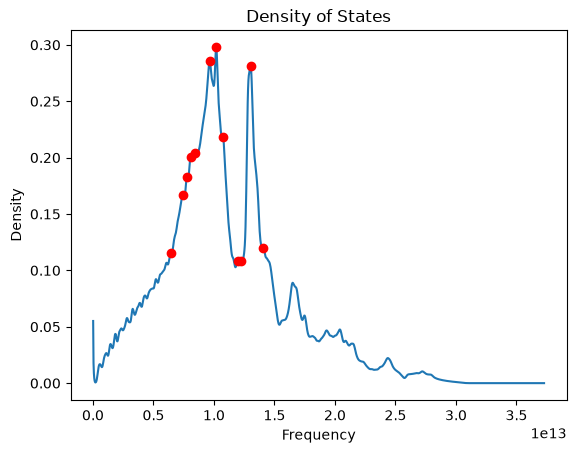

In [24]:
mp_id = "mp-6947"
temp = 300
data,peak_indices, peak_properties = peak_finder(mp_id, temp, num_peaks=12)
save_peak_data(mp_id, temp, peak_indices, peak_properties, data["projection"]["total"]["frequencies"])

Fetching from existing file...


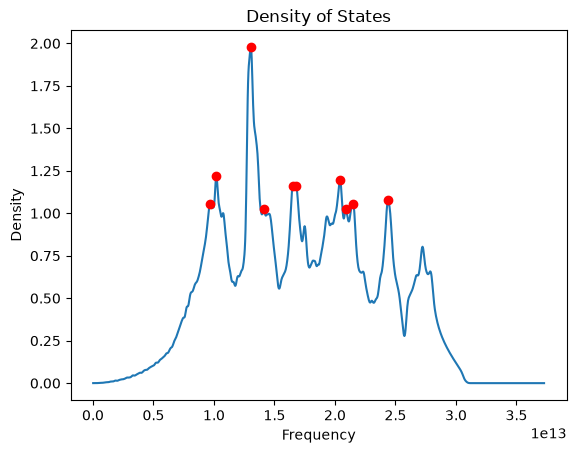

In [25]:
mp_id = "mp-6947"
temp = "athermal"
data,peak_indices, peak_properties = peak_finder(mp_id, temp, num_peaks=10)
save_peak_data(mp_id, temp, peak_indices, peak_properties, data["projection"]["total"]["frequencies"])

Fetching from existing file...
mp-66: 2 atoms. Raw DOS integral: 6.0000 (Target 3N = 6.0000) ratio: 1.0000
Fitting 6 pseudo-Voigt peaks at [23.07 30.36 32.55 34.7  36.98 39.29] THz
Fitted DOS integral: 6.085007 (Target = 6.000000)
Peak 1: Center = 23.072, Amplitude = 0.1992, FWHM left/right = 13.406/13.406 (asymmetry 1.00), eta = 0.00, Integrated Modes = 2.84
Peak 2: Center = 30.357, Amplitude = 0.2421, FWHM left/right = 1.325/1.325 (asymmetry 1.00), eta = 0.00, Integrated Modes = 0.34
Peak 3: Center = 32.545, Amplitude = 0.1894, FWHM left/right = 0.748/0.748 (asymmetry 1.00), eta = 0.00, Integrated Modes = 0.15
Peak 4: Center = 34.704, Amplitude = 0.4690, FWHM left/right = 1.880/1.880 (asymmetry 1.00), eta = 0.00, Integrated Modes = 0.94
Peak 5: Center = 36.982, Amplitude = 0.8734, FWHM left/right = 1.673/1.673 (asymmetry 1.00), eta = 0.00, Integrated Modes = 1.56
Peak 6: Center = 39.290, Amplitude = 0.3773, FWHM left/right = 0.637/0.637 (asymmetry 1.00), eta = 0.00, Integrated Modes 

/var/folders/st/tjxxkn455hv8cj57y4wynzgh0000gn/T/ipykernel_93347/3612394670.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


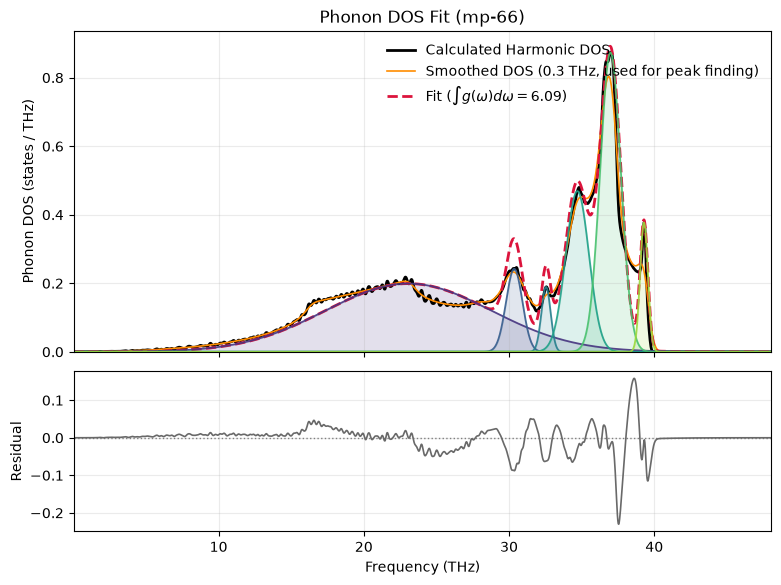

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d


# --- 1. Model Definitions ---
n_pv_params = 5  # amp, center, fwhm_left, fwhm_right, eta


def asymmetric_pseudo_voigt(w, amp, center, fwhm_left, fwhm_right, eta):
  """Asymmetric (split) pseudo-Voigt peak: separate widths below and above the centre, so a peak can rise
  slowly on one side and fall sharply on the other."""
  half_w = np.where(w < center, fwhm_left, fwhm_right) / 2.0
  x = (w - center) / half_w
  lorentz = 1.0 / (1.0 + x**2)
  gauss = np.exp(-np.log(2.0) * x**2)
  return amp * (eta * lorentz + (1.0 - eta) * gauss)


def total_dos_model(w, *params):
  """Sum of N asymmetric pseudo-Voigt peaks."""
  y = np.zeros_like(w, dtype=float)
  for i in range(0, len(params), n_pv_params):
    y += asymmetric_pseudo_voigt(w, *params[i : i + n_pv_params])
  return y


def fit_dos(
    mp_id,
    n_peaks=9,                 # number of pseudo-Voigt peaks to fit
    smoothing=0.3,             # THz, width of the Gaussian smoothing applied before taking the curvature
    center_window=0.5,         # THz, how far each peak centre may move from where it was detected; None = free
    amp_range=(0.5, 1.1),      # each peak's amplitude stays within these fractions of the DOS where it was detected; None = free
    gaussian_only=False,       # True: fix eta = 0, so every peak is a pure Gaussian
    symmetric=False,           # True: force fwhm_right = fwhm_left, so every peak is symmetric
):
  """Fit the athermal total phonon DOS of a Materials Project entry with asymmetric pseudo-Voigt peaks.
  Prints a summary, plots the fit, and returns a dict with the fitted parameters and curves."""

  # --- 2. Load Phonon DOS Data & Set Unit Cell Atom Count ---
  data = dos_stats.dos_stats_analysis(mp_id=mp_id)
  N_atoms = len([site for site in data["projection"] if site != "total"])  # atoms in the cell the DOS is for
  target_integral = 3.0 * N_atoms  # DOS is in states/THz, so integrates to 3N over THz
  dos = data["projection"]["total"]["stats"]["athermal"]["densities"]
  freq = data["projection"]["total"]["frequencies"] / 1E12  # dos_stats gives Hz; fit in THz

  print(f"{mp_id}: {N_atoms} atoms. Raw DOS integral: {np.trapezoid(dos, freq):.4f} (Target 3N = {target_integral:.4f})",
        f"ratio: {np.trapezoid(dos, freq) / target_integral:.4f}")

  # --- 3. Set Initial Guesses & Bounds ---
  # find peaks AND shoulders from the curvature of a lightly smoothed DOS: both show up as places where the DOS bends
  # downwards most strongly (maxima of -d2g/dw2). Smoothing stops small wiggles in the data being picked as peaks.
  dos_smooth = gaussian_filter1d(dos, smoothing / (freq[1] - freq[0]))
  neg_curvature = -np.gradient(np.gradient(dos_smooth, freq), freq)
  peaks, props = find_peaks(neg_curvature, prominence=0.01 * np.max(neg_curvature))
  peaks = np.sort(peaks[np.argsort(props["prominences"])[::-1][:n_peaks]])  # keep the n_peaks strongest
  print(f"Fitting {len(peaks)} pseudo-Voigt peaks at {np.round(freq[peaks], 2)} THz")

  def center_bounds(f0):
    if center_window is None:
      return (freq[0], freq[-1])
    return (max(freq[0], f0 - center_window), min(freq[-1], f0 + center_window))

  def amp_bounds(p):
    if amp_range is None:
      return (0.0, None)
    # the DOS can be higher anywhere in the centre window, so the upper limit uses the window's maximum
    lo_f, hi_f = (freq[p] - center_window, freq[p] + center_window) if center_window is not None else (freq[p], freq[p])
    in_window = (freq >= lo_f) & (freq <= hi_f)
    return (amp_range[0] * dos[p], amp_range[1] * max(dos[p], dos[in_window].max()))

  p0, bounds = [], []
  fwhm_guess = (freq[-1] - freq[0]) / 25.0
  fwhm_min = 2 * (freq[1] - freq[0])  # a peak narrower than ~2 grid points falls between the data points
  for p in peaks:
    eta0 = 0.0 if gaussian_only else 0.5
    p0.extend([dos[p], freq[p], fwhm_guess, fwhm_guess, eta0])  # start symmetric; the fit sets the asymmetry
    bounds.extend([
        amp_bounds(p),           # amp stays near the DOS height where the peak was detected
        center_bounds(freq[p]),  # center stays near the detected peak
        (fwhm_min, None),        # fwhm_left: at least 2 grid points
        (fwhm_guess, fwhm_guess) if symmetric else (fwhm_min, None),  # fwhm_right (unused if symmetric: copied from left)
        (0.0, 0.0) if gaussian_only else (0.0, 1.0),  # eta fixed at 0 (Gaussian) or free in [0, 1]
    ])

  p0 = np.array(p0, dtype=float)

  # --- 4. Run Optimisation (L-BFGS-B, parameter bounds only) ---
  def tie_widths(params):
    """For symmetric peaks, the right width is set equal to the left width (fwhm_left is the one that is fitted)."""
    if not symmetric:
      return params
    params = np.array(params, dtype=float)
    params[3::n_pv_params] = params[2::n_pv_params]
    return params

  def objective(params):
    y_pred = total_dos_model(freq, *tie_widths(params))
    return np.sum((dos - y_pred) ** 2)

  res = minimize(
      objective,
      p0,
      method="L-BFGS-B",
      bounds=bounds,
      options={"maxiter": 2000, "maxfun": 50000, "ftol": 1e-10},
  )

  if not res.success:
    print(f"Warning: Optimisation message -> {res.message}")

  pv_fit = tie_widths(res.x)
  fitted_dos = total_dos_model(freq, *pv_fit)
  residuals = dos - fitted_dos

  # --- 5. Print Fitted Summary & Integrated Area Check ---
  fitted_area = np.trapezoid(fitted_dos, freq)
  print(f"Fitted DOS integral: {fitted_area:.6f} (Target = {target_integral:.6f})")

  for idx, i in enumerate(range(0, len(pv_fit), n_pv_params)):
    amp, center, fwhm_left, fwhm_right, eta = pv_fit[i : i + n_pv_params]
    peak_curve = asymmetric_pseudo_voigt(freq, *pv_fit[i : i + n_pv_params])
    peak_modes = np.trapezoid(peak_curve, freq)
    print(
        f"Peak {idx+1}: Center = {center:.3f}, Amplitude = {amp:.4f}, FWHM left/right = {fwhm_left:.3f}/{fwhm_right:.3f} "
        f"(asymmetry {fwhm_right / fwhm_left:.2f}), eta = {eta:.2f}, Integrated Modes = {peak_modes:.2f}"
    )

  # --- 6. Visualise the Fit, Components & Residuals ---
  fig, (ax1, ax2) = plt.subplots(
      2,
      1,
      figsize=(9, 6.5),
      sharex=True,
      gridspec_kw={"height_ratios": [2, 1], "hspace": 0.08},
  )

  ax1.plot(freq, dos, color="black", linewidth=2, label="Calculated Harmonic DOS")
  ax1.plot(freq, dos_smooth, color="darkorange", linewidth=1.2, label=f"Smoothed DOS ({smoothing} THz, used for peak finding)")
  ax1.plot(
      freq,
      fitted_dos,
      color="crimson",
      linestyle="--",
      linewidth=2,
      label=f"Fit ($\\int g(\\omega)d\\omega = {fitted_area:.2f}$)",
  )

  colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(pv_fit) // n_pv_params))
  for idx, i in enumerate(range(0, len(pv_fit), n_pv_params)):
    peak_curve = asymmetric_pseudo_voigt(freq, *pv_fit[i : i + n_pv_params])
    ax1.plot(freq, peak_curve, color=colors[idx], linewidth=1.3, alpha=0.9)
    ax1.fill_between(freq, 0, peak_curve, color=colors[idx], alpha=0.15)

  ax1.set_ylabel("Phonon DOS (states / THz)")
  ax1.set_title(f"Phonon DOS Fit ({mp_id})")
  ax1.legend(frameon=False, loc="upper right")
  ax1.set_ylim(bottom=0)
  ax1.grid(alpha=0.25)

  ax2.axhline(0, color="gray", linestyle=":", linewidth=1)
  ax2.plot(freq, residuals, color="dimgray", linewidth=1.2)
  ax2.set_xlabel("Frequency (THz)")
  ax2.set_ylabel("Residual")
  ax2.set_xlim(freq[0], freq[-1])
  ax2.grid(alpha=0.25)

  plt.tight_layout()
  plt.show()

  return {"mp_id": mp_id, "freq": freq, "dos": dos, "dos_smooth": dos_smooth, "params": pv_fit,
          "fitted_dos": fitted_dos, "residuals": residuals, "fitted_area": fitted_area, "result": res}


fit_mp66 = fit_dos("mp-66", n_peaks=6, smoothing=0.3, center_window=0.0, amp_range=(1.0, 1.0), gaussian_only=True, symmetric=True)

## Testing the fit on the other materials

`fit_dos` takes the same settings as the mp-66 fit above as keyword arguments (`n_peaks`, `smoothing`, `center_window`, ...). Each material is run first with the mp-66 defaults, then with settings adjusted for it.

Fetching from existing file...
mp-3953: 10 atoms. Raw DOS integral: 30.0000 (Target 3N = 30.0000) ratio: 1.0000
Fitting 9 pseudo-Voigt peaks at [ 5.71  8.83  9.31 20.58 22.86 25.05 28.83 32.31 42.77] THz
Fitted DOS integral: 30.372378 (Target = 30.000000)
Peak 1: Center = 5.714, Amplitude = 2.6111, FWHM left/right = 5.962/5.962 (asymmetry 1.00), eta = 0.00, Integrated Modes = 16.37
Peak 2: Center = 8.831, Amplitude = 6.6844, FWHM left/right = 0.371/0.371 (asymmetry 1.00), eta = 0.00, Integrated Modes = 2.64
Peak 3: Center = 9.311, Amplitude = 2.5447, FWHM left/right = 0.194/0.194 (asymmetry 1.00), eta = 0.00, Integrated Modes = 0.53
Peak 4: Center = 20.583, Amplitude = 11.6765, FWHM left/right = 0.323/0.323 (asymmetry 1.00), eta = 0.00, Integrated Modes = 4.01
Peak 5: Center = 22.862, Amplitude = 0.0000, FWHM left/right = 2.211/2.211 (asymmetry 1.00), eta = 0.00, Integrated Modes = 0.00
Peak 6: Center = 25.050, Amplitude = 7.9694, FWHM left/right = 0.234/0.234 (asymmetry 1.00), eta = 0

/var/folders/st/tjxxkn455hv8cj57y4wynzgh0000gn/T/ipykernel_93347/3612394670.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


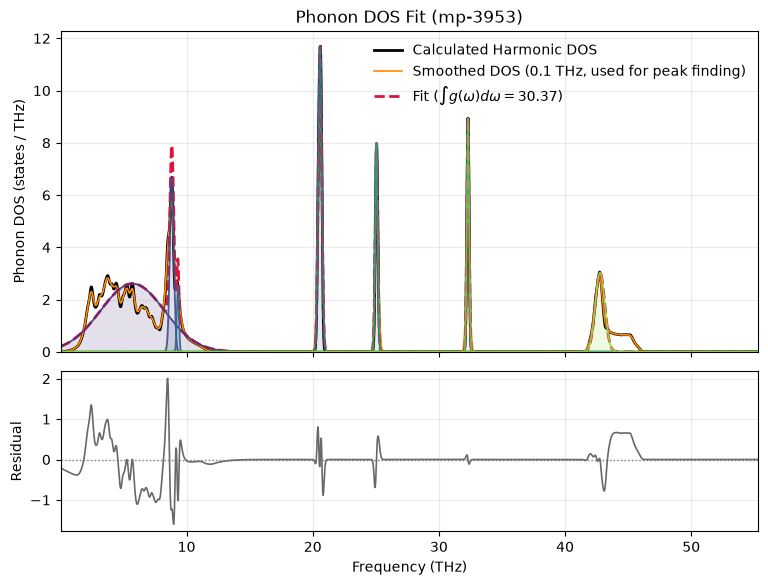

In [18]:
# mp-3953: very sharp, near-molecular optical peaks, so less smoothing and more peaks.
fit_mp3953 = fit_dos("mp-3953", n_peaks=9, smoothing=0.1, center_window=0.0, amp_range=(1.0, 1.0), gaussian_only=True, symmetric=True)

Fetching from existing file...
mp-6947: 6 atoms. Raw DOS integral: 18.0000 (Target 3N = 18.0000) ratio: 1.0000
Fitting 11 pseudo-Voigt peaks at [10.21 10.81 12.85 13.57 14.65 16.48 17.53 20.43 21.54 24.39 27.24] THz
Fitted DOS integral: 18.105759 (Target = 18.000000)
Peak 1: Center = 10.211, Amplitude = 1.2222, FWHM left/right = 3.246/3.246 (asymmetry 1.00), eta = 0.00, Integrated Modes = 4.22
Peak 2: Center = 10.810, Amplitude = 0.9877, FWHM left/right = 0.060/0.060 (asymmetry 1.00), eta = 0.00, Integrated Modes = 0.06
Peak 3: Center = 12.849, Amplitude = 1.8292, FWHM left/right = 0.552/0.552 (asymmetry 1.00), eta = 0.00, Integrated Modes = 1.07
Peak 4: Center = 13.568, Amplitude = 1.3761, FWHM left/right = 0.737/0.737 (asymmetry 1.00), eta = 0.00, Integrated Modes = 1.08
Peak 5: Center = 14.647, Amplitude = 0.9848, FWHM left/right = 1.283/1.283 (asymmetry 1.00), eta = 0.00, Integrated Modes = 1.35
Peak 6: Center = 16.476, Amplitude = 1.1488, FWHM left/right = 1.034/1.034 (asymmetry 1

/var/folders/st/tjxxkn455hv8cj57y4wynzgh0000gn/T/ipykernel_93347/3612394670.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


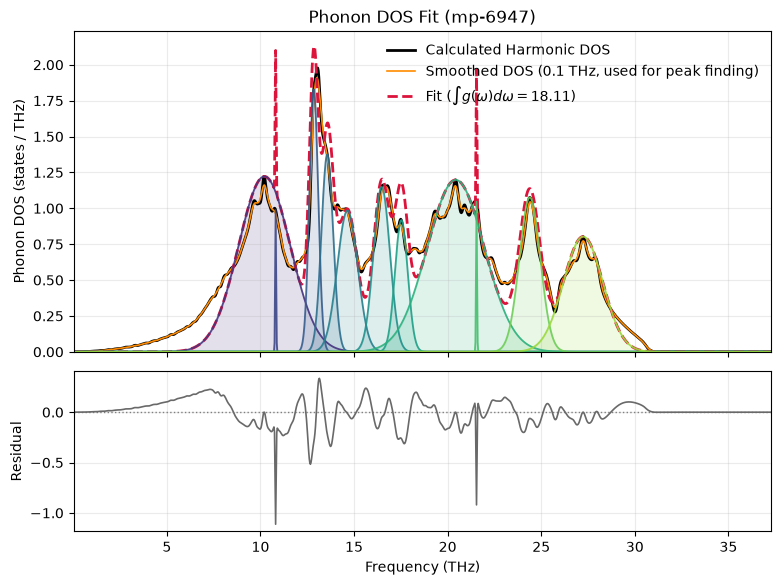

In [19]:
# mp-6947: two more peaks cover the 22 THz shoulder and the tail at the top of the spectrum (~30 THz).
fit_mp6947 = fit_dos("mp-6947", n_peaks=11, smoothing=0.1, center_window=0.0, amp_range=(1.0, 1.0), gaussian_only=True, symmetric=True)